# 2. fasea — Entrenamendua, esperimentu osoa (offline)

Koaderno hau enunciatuak eskatzen duen `02_training.ipynb` entregagarria
da, **logika osoarekin ikusgai**: iturburuaren egiaztapena, partizioak,
ezaugarri fisikoak, 10 espezifikazioen bilaketa 4-fold CVarekin (CG08),
atalase-tuninga, SMOTENC konparazioa (train barruan soilik), Isolation
Forest anomalia-kanala (CG09) eta kalibrazio-diagnostiko bat.

Estiloa **inline + egiaztapena** da: ziegetan kode osoa irakurtzen da, eta
azpian baieztapenak datoz emaitza proiektuko moduluen (`scoring`,
`cnc_guard`, `scripts`) berdina dela. Ez da logika bikoiztu bat: iturri
kanonikoa moduluek izaten jarraitzen dute, eta koadernoak hori frogatzen du.

Ohartxoak, irakurtzen hasi aurretik:

- Partizio kanonikoak: 5600 fit / 1200 garapen-baliozkotze / 1200 baztertua.
  Bazterketa (aurretik ikuskatutako testa) ez da ukitzen.
- Demo-ereduak ez dira sustatzen: `CG04_DEVELOPMENT_ONLY` rolak
  paketatzailearen ezetza jasotzen du, eta ziegi batean erakusten da.
- Baliozkotze osoa minutu batzuk behar ditu (~6-10 min, CVa dela eta);
  bilaketako ziegi bakoitzak aurrerapena inprimatzen du.
- Kalibrazio nested osoa sealed research azterketan dago (CG34); hemen
  diagnostiko garden bat dago, ez haren bikoizketa.


## 1. Ingurunea eta erroa

Erroa biltegitik edo `notebooks/`-tik ebazten da. Ez dago instalaziorik
ziegetan. Kontratu-konstanteak (`INPUT_FEATURES`) `scoring.scope`-tik
inportatzen dira; gainerako logika ziegetan dago ikusgai.


In [1]:
import sys
from pathlib import Path

ROOT = (
    Path.cwd()
    if (Path.cwd() / "data/ai4i2020_train.csv").is_file()
    else Path.cwd().parent
)
sys.path.insert(0, str(ROOT))
print("ROOT:", ROOT)

import joblib
import numpy as np
import pandas as pd
import sklearn

from scoring.scope import INPUT_FEATURES

print("python:", sys.version.split()[0])
print("sklearn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("joblib:", joblib.__version__)
print("INPUT_FEATURES:", INPUT_FEATURES)


ROOT: /home/tears/bigdata/01_Erronka1_CNC_Guard/B-taldea


python: 3.12.14
sklearn: 1.5.0
pandas: 2.2.2
numpy: 1.26.4
joblib: 1.5.3
INPUT_FEATURES: ['air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min', 'machine_type']


## 2. Iturburu onartua: SHA-256 eta eskema, inline

Fitxategiaren byte-exakten SHA-256a eta eskema ziegan bertan egiaztatzen
dira. Azpian, emaitza `load_training_source()` moduluaren berdin-berdina
dela baieztatzen da.


In [2]:
import hashlib
from io import BytesIO

DATA = ROOT / "data/ai4i2020_train.csv"
APPROVED_SHA256 = "1cce2859f4833b63dbf0992868884e5deac6f79e4d74a245abbc484d34e396ce"

raw = DATA.read_bytes()
digest = hashlib.sha256(raw).hexdigest()
print("SHA-256 bat dator:", digest == APPROVED_SHA256)
assert digest == APPROVED_SHA256, "bakarrik iturburu onartua erabil daiteke"

frame = pd.read_csv(BytesIO(raw))
assert len(frame) == 8000, "8000 errenkada behar dira"
assert set(INPUT_FEATURES + ["machine_failure"]) <= set(frame.columns)
print("eskema: OK, 8000 errenkada")

from scoring.scope import load_training_source

pd.testing.assert_frame_equal(frame, load_training_source(DATA))
print("egiaztapena: inline == load_training_source(): OK")


SHA-256 bat dator: True
eskema: OK, 8000 errenkada
egiaztapena: inline == load_training_source(): OK


## 3. Partizio kanonikoak: logika inline + bide ofiziala

Zatiketa bera ziegan ikusgai: %70 fit, gainerako %30a erdi banatuta
(garapen-baliozkotze / baztertua), 42 haziarekin eta estratifikatuta.
Azpian hiru egiaztapen: moduluaren parekoa, disjuntzioa/estaldura, eta
`cg04_preparation` script ofizialaren hashes ordenatuak.


In [3]:
from sklearn.model_selection import train_test_split

SEED = 42
assert frame.machine_failure.isna().sum() == 0
assert set(frame.machine_failure.unique()) == {0, 1}
assert np.isfinite(frame[["air_temp_K", "process_temp_K", "rpm", "torque_Nm", "tool_wear_min"]].to_numpy(dtype=float)).all()

train, remaining = train_test_split(frame, test_size=0.3, random_state=SEED, stratify=frame.machine_failure)
validation, excluded = train_test_split(remaining, test_size=0.5, random_state=SEED, stratify=remaining.machine_failure)

for name, part in (("fit", train), ("garapen-baliozkotze", validation), ("baztertua", excluded)):
    positives = int(part.machine_failure.sum())
    print(f"{name}: {len(part)} errenkada, {positives} positibo ({positives / len(part):.2%})")

from scoring.preparation import split_development

for inline_part, module_part in zip((train, validation, excluded), split_development(frame)):
    pd.testing.assert_frame_equal(inline_part, module_part)
print("egiaztapena: inline == split_development(): OK")

sets = [set(part.index) for part in (train, validation, excluded)]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
assert set.union(*sets) == set(frame.index)
print("egiaztapena: disjuntuak eta estaldura osoa: OK")


fit: 5600 errenkada, 190 positibo (3.39%)
garapen-baliozkotze: 1200 errenkada, 41 positibo (3.42%)
baztertua: 1200 errenkada, 40 positibo (3.33%)
egiaztapena: inline == split_development(): OK
egiaztapena: disjuntuak eta estaldura osoa: OK


In [4]:
import json
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "scripts.cg04_preparation"],
    cwd=ROOT,
    check=True,
    capture_output=True,
    text=True,
)
official = json.loads(result.stdout)["active"]
print("fit:", official["fit"]["rows"], "| baliozkotze:", official["development_validation"]["rows"],
      "| baztertua:", official["excluded_previously_inspected_test"]["rows"])
assert (official["fit"]["rows"], official["development_validation"]["rows"]) == (5600, 1200)
assert official["excluded_rows_in_fit"] == 0
print("egiaztapena: script ofizialaren partizioak bat datoz: OK")


fit: 5600 | baliozkotze: 1200 | baztertua: 1200
egiaztapena: script ofizialaren partizioak bat datoz: OK


## 4. Klase-desoreka eta accuracy-ren tranpa

Hutsegiteak %3,4 inguru dira. Beti "0" aurresaten duen eredu tonto batek
%96 inguruko accuracy-a luke, baina recall 0: ez luke hutsegite bakar
bat ere harrapatuko. Horregatik erabakitzen da recall, precision, F2 eta
nahasmen-matrizearekin, ez accuracy hutsarekin.


In [5]:
y_train = train.machine_failure
y_val = validation.machine_failure.to_numpy()
print(f"Beti-0 accuracy baliozkotzean: {(y_val == 0).mean():.4f} (tranpa, recall 0.0)")


Beti-0 accuracy baliozkotzean: 0.9658 (tranpa, recall 0.0)


## 5. Ezaugarri fisikoak: formulak inline + egiaztapena

Hiru ezaugarri eratorriak, unitateekin:

- `temp_diff = process_temp_K - air_temp_K` (K).
- `power_W = rpm * torque_Nm * (2*pi/60)` (W, potentzia mekaniko ideala).
- `wear_torque = tool_wear_min * torque_Nm` (proxy bat).

Etiketak, azpimotak, denbora-zigilurik eta `machine_id`-rik ez da sartzen.
Azpian, `scoring.preparation.features()` moduluaren berdina dela frogatzen da.


In [6]:
SENSORS = ["air_temp_K", "process_temp_K", "rpm", "torque_Nm", "tool_wear_min"]
DERIVED = ["temp_diff", "power_W", "wear_torque"]

from scoring.preparation import DERIVED as DERIVED_MOD, SENSORS as SENSORS_MOD, features as features_mod

assert SENSORS == SENSORS_MOD and DERIVED == DERIVED_MOD

sample = train.head(3)
inline = sample[SENSORS + ["machine_type"]].copy()
inline["temp_diff"] = inline.process_temp_K - inline.air_temp_K
inline["power_W"] = inline.rpm * inline.torque_Nm * (2 * np.pi / 60)
inline["wear_torque"] = inline.tool_wear_min * inline.torque_Nm
pd.testing.assert_frame_equal(inline, features_mod(sample))
print(inline[DERIVED].round(2).to_string())
print("egiaztapena: formulak inline == features(): OK")


      temp_diff  power_W  wear_torque
1386        8.9  7761.30       8399.7
4930       10.1  5881.25       1955.7
2745        8.8  3882.37       3927.1
egiaztapena: formulak inline == features(): OK


## 6. Bilaketa osoa (CG08): espezifikazioak, fold-ak eta zaintza

10 espezifikazio: beti-0 (dummy), erregresio logistikoa eta 8 Random
Forest (fisikoak bai/ez × pisuak bai/ez × sakonera 8/12). 4-fold CV
estratifikatua train-ean, 42 haziarekin. Aurreko zaintza: ezaugarri
sinadura bikoizturik ez dagoela partizioetan.


In [7]:
from sklearn.model_selection import StratifiedKFold

specs = [("dummy", False, None, 12), ("logistic", False, "balanced", 12)]
specs += [
    ("rf", physical, weight, depth)
    for physical in (False, True)
    for weight in (None, "balanced")
    for depth in (8, 12)
]
print("espezifikazioak:", len(specs))
for i, (kind, physical, weight, depth) in enumerate(specs):
    print(f"  [{i}] {kind} fisikoak={physical} pisuak={weight} sakonera={depth}")

signature = pd.util.hash_pandas_object(frame[SENSORS + ["machine_type"]], index=False)
assert not signature.duplicated().any(), "sinadura bikoiztuak: zatiketa agrupatua behar da"
print("zaintza: sinadura bikoizturik ez: OK")

cv = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED).split(train, y_train))
print("fold-ak:", len(cv), "| 1. fold-a: fit", len(cv[0][0]), "held", len(cv[0][1]))


espezifikazioak: 10
  [0] dummy fisikoak=False pisuak=None sakonera=12
  [1] logistic fisikoak=False pisuak=balanced sakonera=12
  [2] rf fisikoak=False pisuak=None sakonera=8
  [3] rf fisikoak=False pisuak=None sakonera=12
  [4] rf fisikoak=False pisuak=balanced sakonera=8
  [5] rf fisikoak=False pisuak=balanced sakonera=12
  [6] rf fisikoak=True pisuak=None sakonera=8
  [7] rf fisikoak=True pisuak=None sakonera=12
  [8] rf fisikoak=True pisuak=balanced sakonera=8
  [9] rf fisikoak=True pisuak=balanced sakonera=12
zaintza: sinadura bikoizturik ez: OK
fold-ak: 4 | 1. fold-a: fit 4200 held 1400


## 7. Pipeline-a, atalasea eta metrikak: funtzioak inline

Bilaketak erabiltzen dituen hiru funtzioak ziegan definitzen dira:
fisika→aurreprozesu→eredua pipeline-a, F2 atalase optimoa eta ebaluazioa
(precision, recall, F1, F2, ROC-AUC, AP, matrizea). 9. atalean moduluen
parekoekin alderatzen dira, emaitza berdinekin.


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


def build_pipeline_inline(kind, physical=False, weight=None, trees=120, depth=12):
    numeric = SENSORS + (DERIVED if physical else [])
    prep = ColumnTransformer(
        [
            ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                                              ("scale", StandardScaler())]), numeric),
            ("type", OneHotEncoder(handle_unknown="ignore"), ["machine_type"]),
        ],
        remainder="drop",
    )
    if kind == "dummy":
        estimator = DummyClassifier(strategy="constant", constant=0)
    elif kind == "logistic":
        estimator = LogisticRegression(class_weight=weight, max_iter=3000, random_state=SEED)
    else:
        estimator = RandomForestClassifier(
            n_estimators=trees, max_depth=depth, min_samples_leaf=2,
            class_weight=weight, random_state=SEED, n_jobs=1,
        )
    return Pipeline([("physics", FunctionTransformer(features_mod, validate=False)),
                     ("preprocess", prep), ("model", estimator)])


def threshold_inline(y, scores, beta=2):
    precision, recall, limits = precision_recall_curve(y, scores)
    b = beta ** 2
    quality = (1 + b) * precision[:-1] * recall[:-1] / np.maximum(b * precision[:-1] + recall[:-1], 1e-15)
    return float(limits[np.argmax(quality)])


def evaluate_inline(y, scores, cutoff):
    prediction = np.asarray(scores) >= cutoff
    return {
        "threshold": float(cutoff),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "f1": float(fbeta_score(y, prediction, beta=1, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, scores)),
        "average_precision": float(average_precision_score(y, scores)),
        "confusion_matrix": confusion_matrix(y, prediction, labels=[0, 1]).tolist(),
    }


print("funtzio inlineak definituta: pipeline, atalasea, ebaluazioa")


funtzio inlineak definituta: pipeline, atalasea, ebaluazioa


## 8. Bilaketaren exekuzioa: OOF fold guztietan

Espezifikazio bakoitzak 4-fold CVa egiten du train-ean (`cross_val_predict`,
fold-etik kanpoko score-ak), eta atalasea F2 optimoarekin aukeratzen da
(dummy-an 0,5 finkoa). Ziegi honek minutu batzuk behar ditu; lerro bakoitza
espezifikazio baten emaitza da.


In [9]:
from sklearn.model_selection import cross_val_predict

search = []
candidates = []
for kind, physical, weight, depth in specs:
    model = build_pipeline_inline(kind, physical, weight, depth=depth)
    oof = cross_val_predict(model, train[INPUT_FEATURES], y_train, cv=cv,
                            method="predict_proba", n_jobs=2)[:, 1]
    cutoff = 0.5 if kind == "dummy" else threshold_inline(y_train, oof)
    metrics = evaluate_inline(y_train, oof, cutoff)
    search.append({"kind": kind, "physical": physical, "class_weight": weight,
                   "max_depth": depth, "oof_selection_metrics": metrics})
    candidates.append(model)
    print(f"{kind} fisikoak={physical} pisuak={weight} sakonera={depth} "
          f"-> OOF AP={metrics['average_precision']:.4f} recall={metrics['recall']:.4f} "
          f"precision={metrics['precision']:.4f} F2={metrics['f2']:.4f}", flush=True)
print("bilaketa osoa: OK")


dummy fisikoak=False pisuak=None sakonera=12 -> OOF AP=0.0339 recall=0.0000 precision=0.0000 F2=0.0000


logistic fisikoak=False pisuak=balanced sakonera=12 -> OOF AP=0.4505 recall=0.5737 precision=0.3597 F2=0.5127


rf fisikoak=False pisuak=None sakonera=8 -> OOF AP=0.7385 recall=0.7579 precision=0.6372 F2=0.7302


rf fisikoak=False pisuak=None sakonera=12 -> OOF AP=0.7682 recall=0.8105 precision=0.5856 F2=0.7527


rf fisikoak=False pisuak=balanced sakonera=8 -> OOF AP=0.6170 recall=0.8263 precision=0.4758 F2=0.7202


rf fisikoak=False pisuak=balanced sakonera=12 -> OOF AP=0.6956 recall=0.8211 precision=0.5417 F2=0.7443


rf fisikoak=True pisuak=None sakonera=8 -> OOF AP=0.9053 recall=0.8737 precision=0.8646 F2=0.8718


rf fisikoak=True pisuak=None sakonera=12 -> OOF AP=0.9090 recall=0.8737 precision=0.8691 F2=0.8728


rf fisikoak=True pisuak=balanced sakonera=8 -> OOF AP=0.8921 recall=0.8526 precision=0.8663 F2=0.8553


rf fisikoak=True pisuak=balanced sakonera=12 -> OOF AP=0.8944 recall=0.8842 precision=0.7887 F2=0.8633


bilaketa osoa: OK


## 9. Irabazlea, doiketa osoa eta egiaztapena moduluekin

Hautaketa OOF AP-aren arabera egiten da (RFen artean, ez baliozkotzean).
Irabazlea train osoan birdoitzen da, eta atalasea baliozkotzean tunetzen
da. Ondoren hiru egiaztapen: pipeline berdinak score berdinak ematen
dituela, eta atalase/metrika funtzio inline-ak moduluen berdinak direla.


In [10]:
eligible = [i for i, r in enumerate(search) if r["kind"] == "rf"]
winner = max(eligible, key=lambda i: search[i]["oof_selection_metrics"]["average_precision"])
w = search[winner]
print(f"irabazlea: [{winner}] rf fisikoak={w['physical']} pisuak={w['class_weight']} "
      f"sakonera={w['max_depth']} OOF AP={w['oof_selection_metrics']['average_precision']:.4f}")

model = candidates[winner].fit(train[INPUT_FEATURES], y_train)
scores = model.predict_proba(validation[INPUT_FEATURES])[:, 1]
cutoff = threshold_inline(y_val, scores)
val_metrics = evaluate_inline(y_val, scores, cutoff)
print(f"baliozkotzea: atalasea={cutoff:.4f} recall={val_metrics['recall']:.4f} "
      f"precision={val_metrics['precision']:.4f} F2={val_metrics['f2']:.4f}")

from scripts.experiment_rf import evaluate as evaluate_mod, pipeline as pipeline_mod, threshold as threshold_mod

reference = pipeline_mod(w["kind"], w["physical"], w["class_weight"], depth=w["max_depth"])
reference.fit(train[INPUT_FEATURES], y_train)
np.testing.assert_array_equal(scores, reference.predict_proba(validation[INPUT_FEATURES])[:, 1])
assert threshold_mod(y_val, scores) == cutoff
assert evaluate_mod(y_val, scores, cutoff) == val_metrics
print("egiaztapena: inline == experiment_rf (pipeline, atalasea, metrikak): OK")


irabazlea: [7] rf fisikoak=True pisuak=None sakonera=12 OOF AP=0.9090


baliozkotzea: atalasea=0.1908 recall=0.7805 precision=0.7805 F2=0.7805


egiaztapena: inline == experiment_rf (pipeline, atalasea, metrikak): OK


## 10. Bilaketaren taula eta txosten sailkatzailea

Bilaketa osoaren laburpena, eta irabazlearen txosten zehatza baliozkotzean.
FN bakoitza geldialdi bat da (1.200 €/h-ko eszenatokian) eta FP bakoitza
alferrikako ikuskapen bat; kostuen xehetasuna
`02_business_costs_evidence.ipynb`-en dago.


In [11]:
rows = [{"espezifikazioa": f"{r['kind']} fis={r['physical']} pisu={r['class_weight']} d={r['max_depth']}",
           "OOF AP": round(r["oof_selection_metrics"]["average_precision"], 4),
           "OOF recall": round(r["oof_selection_metrics"]["recall"], 4),
           "OOF precision": round(r["oof_selection_metrics"]["precision"], 4),
           "OOF F2": round(r["oof_selection_metrics"]["f2"], 4)} for r in search]
print(pd.DataFrame(rows).to_string(index=False))

from sklearn.metrics import classification_report

prediction = scores >= cutoff
print(f"\nF2 atalase optimoa (baliozkotzea): {cutoff:.4f}")
print(classification_report(y_val, prediction, target_names=["OK (0)", "hutsegitea (1)"], digits=4))
matrix = confusion_matrix(y_val, prediction, labels=[0, 1])
print("Nahasmen-matrizea [[TN, FP], [FN, TP]]:")
print(matrix)


                       espezifikazioa  OOF AP  OOF recall  OOF precision  OOF F2
       dummy fis=False pisu=None d=12  0.0339      0.0000         0.0000  0.0000
logistic fis=False pisu=balanced d=12  0.4505      0.5737         0.3597  0.5127
           rf fis=False pisu=None d=8  0.7385      0.7579         0.6372  0.7302
          rf fis=False pisu=None d=12  0.7682      0.8105         0.5856  0.7527
       rf fis=False pisu=balanced d=8  0.6170      0.8263         0.4758  0.7202
      rf fis=False pisu=balanced d=12  0.6956      0.8211         0.5417  0.7443
            rf fis=True pisu=None d=8  0.9053      0.8737         0.8646  0.8718
           rf fis=True pisu=None d=12  0.9090      0.8737         0.8691  0.8728
        rf fis=True pisu=balanced d=8  0.8921      0.8526         0.8663  0.8553
       rf fis=True pisu=balanced d=12  0.8944      0.8842         0.7887  0.8633

F2 atalase optimoa (baliozkotzea): 0.1908
                precision    recall  f1-score   support

        O

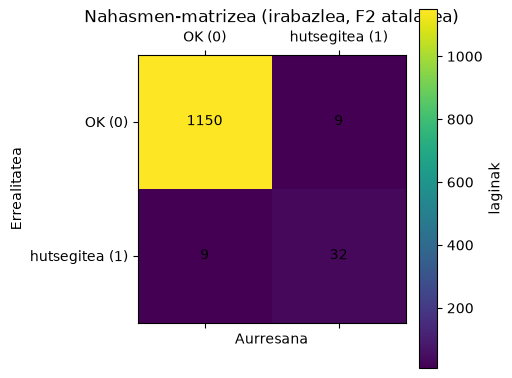

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
display = ax.matshow(matrix)
fig.colorbar(display, ax=ax, label="laginak")
ax.set(title="Nahasmen-matrizea (irabazlea, F2 atalasea)", xlabel="Aurresana", ylabel="Errealitatea",
       xticks=[0, 1], yticks=[0, 1],
       xticklabels=["OK (0)", "hutsegitea (1)"], yticklabels=["OK (0)", "hutsegitea (1)"])
for row in range(2):
    for col in range(2):
        ax.text(col, row, matrix[row, col], ha="center", va="center")
plt.show()


## 11. Aldagaien garrantzia (interpretazio fisikoa)

Irabazlearen `feature_importances_` balioak, aurreprozesuaren irteerako
izenekin lerrokatuta. Interpretazioa fisikoa/industriala izan behar da
(tenperaturak, momentua, higadura), ez izen-hurrenkera hutsa.


      aldagaia  garrantzia
machine_type_H      0.0046
machine_type_M      0.0086
machine_type_L      0.0157
process_temp_K      0.0326
    air_temp_K      0.0419
 tool_wear_min      0.0435
     torque_Nm      0.1366
     temp_diff      0.1369
           rpm      0.1611
       power_W      0.1838
   wear_torque      0.2344


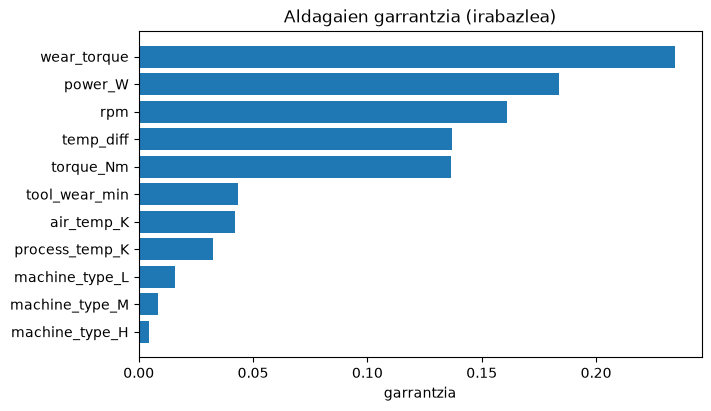

In [13]:
names = model.named_steps["preprocess"].get_feature_names_out()
importances = model.named_steps["model"].feature_importances_
ranking = (pd.DataFrame({"aldagaia": [name.split("__", 1)[-1] for name in names], "garrantzia": importances})
             .sort_values("garrantzia", ascending=True))
print(ranking.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.barh(ranking["aldagaia"], ranking["garrantzia"])
ax.set(title="Aldagaien garrantzia (irabazlea)", xlabel="garrantzia")
plt.show()


## 12. SMOTENC konparazioa: laginketa train-fold-aren barruan soilik

SMOTENCk jatorrizko sentsoreak eta `machine_type` kategorikoa lagintzen
ditu %20ko estrategiarekin (k=3); fisika deribatua gero birkalkulatzen
da, pipeline-aren barruan. CVko fold berberak erabiltzen dira (CG08koak),
eta baliozkotzeak benetako banaketa gordetzen du: horrela ez dago data
leakage-ik. Azpian, `make_smotenc()` moduluaren score berdinak ematen
dituela egiaztatzen da.


In [14]:
import imblearn
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

impute = ColumnTransformer(
    [("sensors", SimpleImputer(strategy="median"), SENSORS),
     ("type", SimpleImputer(strategy="most_frequent"), ["machine_type"])],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

smote_inline = ImbPipeline([
    ("impute", impute),
    ("sampler", SMOTENC(categorical_features=["machine_type"], sampling_strategy=0.2,
                        k_neighbors=3, random_state=SEED)),
    *build_pipeline_inline("rf", True, None, depth=12).steps,
])

oof_smote = cross_val_predict(smote_inline, train, y_train, cv=cv,
                              method="predict_proba", n_jobs=2)[:, 1]
cut_smote = threshold_inline(y_train, oof_smote)
metrics_smote = evaluate_inline(y_train, oof_smote, cut_smote)
print(f"SMOTE OOF: AP={metrics_smote['average_precision']:.4f} recall={metrics_smote['recall']:.4f} "
      f"precision={metrics_smote['precision']:.4f} F2={metrics_smote['f2']:.4f} (imbalanced-learn {imblearn.__version__})")

smote_inline.fit(train, y_train)
scores_smote = smote_inline.predict_proba(validation)[:, 1]
cut_val_smote = threshold_inline(y_val, scores_smote)
diag_smote = evaluate_inline(y_val, scores_smote, cut_val_smote)
print(f"SMOTE baliozkotzea: atalasea={cut_val_smote:.4f} recall={diag_smote['recall']:.4f} "
      f"precision={diag_smote['precision']:.4f} F2={diag_smote['f2']:.4f}")

from scripts.experiment_smotenc import make_smotenc

reference_smote = make_smotenc()
reference_smote.fit(train, y_train)
np.testing.assert_array_equal(scores_smote, reference_smote.predict_proba(validation)[:, 1])
print("egiaztapena: inline == make_smotenc(): OK")
print("muga: sentsore sintetikoek ez dira hutsegite behatu berriak; ez da sustatzen automatikoki.")


SMOTE OOF: AP=0.8929 recall=0.8474 precision=0.8750 F2=0.8528 (imbalanced-learn 0.14.2)


SMOTE baliozkotzea: atalasea=0.3426 recall=0.8049 precision=0.6226 F2=0.7604


egiaztapena: inline == make_smotenc(): OK
muga: sentsore sintetikoek ez dira hutsegite behatu berriak; ez da sustatzen automatikoki.


## 13. Anomalia-kanala (CG09): Isolation Forest, hutsegite-probabilitate gabe

Bigarren kanala normalekin soilik doitu da (ez da hutsegiterik ikusten
fit-ean), irabazlearen aurreprozesu bera berrerabilita. Score-a
`-score_samples` da (handiago = arraroago), eta atalasea baliozkotzeko
normalen %99 kuantila da. Etiketa-diagnostikoa proxy bat da, ez anomalia
egia: kanal honek ezin ditu RF alarmak isilarazi. Azpian `fit_normal()`
moduluaren score berdinak ematen dituela frogatzen da.


In [15]:
from sklearn.ensemble import IsolationForest

normal_train = train.loc[y_train.eq(0)]
print("normal fit errenkadak:", len(normal_train))
assert not normal_train.empty

prep_inline = build_pipeline_inline("rf", True)[:-1]
if_inline = Pipeline([("preprocess", prep_inline),
                      ("anomaly", IsolationForest(n_estimators=200, random_state=SEED,
                                                  contamination="auto", n_jobs=1))])
if_inline.fit(normal_train[INPUT_FEATURES])
scores_if = -if_inline.score_samples(validation[INPUT_FEATURES])

normal_val = y_val == 0
cut_if = float(np.quantile(scores_if[normal_val], 0.99, method="higher"))
flags_if = scores_if >= cut_if
print(f"IF atalasea (normalen %99 kuantila): {cut_if:.4f}")
print(f"normalen alerta-frakzio behatua: {flags_if[normal_val].mean():.4f} "
      f"({int(flags_if[normal_val].sum())}/{int(normal_val.sum())})")

diag_if = evaluate_inline(y_val, scores_if, cut_if)
print(f"IF etiketa-diagnostikoa (proxy): recall={diag_if['recall']:.4f} precision={diag_if['precision']:.4f}")

from scripts.experiment_anomaly import fit_normal

reference_if, _ = fit_normal(train)
np.testing.assert_array_equal(scores_if, -reference_if.score_samples(validation[INPUT_FEATURES]))
print("egiaztapena: inline == fit_normal(): OK")


normal fit errenkadak: 5410


IF atalasea (normalen %99 kuantila): 0.6145
normalen alerta-frakzio behatua: 0.0104 (12/1159)
IF etiketa-diagnostikoa (proxy): recall=0.0244 precision=0.0769


egiaztapena: inline == fit_normal(): OK


## 14. Kalibrazio-diagnostikoa: score-ak ez daude kalibratuta

RF irabazlearen score-ak ez dira arrisku-probabilitate kalibratuak
(`class_weight`-ek kalibrazioa mugitzen du): kontratuak
`uncalibrated_current_state_score` dio. Taula eta figura honek score
kuintilen arabera behatutako hutsegite-frakzioa erakusten dute
garapen-baliozkotzean. Kalibrazio nested osoa (raw/sigmoid/isotonic)
sealed research azterketan dago (CG34, `scripts.ml_study` bereizin
ingurunean); ez da hemen bikoizten, eta atal honek ez du moduluzko
parekorik — gardentasunez adierazten da.


                                    laginak  batez_score  behatutako_frakzio
bina                                                                        
(-0.0009956400000000001, 9.53e-05]      240       0.0001              0.0000
(9.53e-05, 0.000204]                    240       0.0001              0.0042
(0.000204, 0.000757]                    240       0.0004              0.0000
(0.000757, 0.00958]                     240       0.0042              0.0000
(0.00958, 0.977]                        240       0.1596              0.1667


/home/tears/bigdata/01_Erronka1_CNC_Guard/B-taldea/.venv/lib/python3.12/site-packages/pandas/core/util/hashing.py:330: RuntimeWarning: invalid value encountered in cast
  vals.astype(str).astype(object), hash_key, encoding


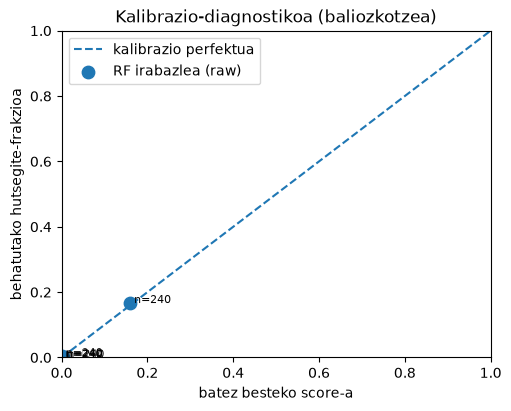

In [16]:
bins = pd.qcut(scores, 5, duplicates="drop")
table = pd.DataFrame({"bina": bins, "score": scores, "etiketa": y_val}).groupby("bina", observed=True).agg(
    laginak=("etiketa", "size"), batez_score=("score", "mean"), behatutako_frakzio=("etiketa", "mean"))
print(table.round(4).to_string())

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.plot([0, 1], [0, 1], linestyle="--", label="kalibrazio perfektua")
ax.scatter(table["batez_score"], table["behatutako_frakzio"], s=80, label="RF irabazlea (raw)")
for (_, row) in table.iterrows():
    ax.text(row["batez_score"], row["behatutako_frakzio"], f" n={int(row['laginak'])}", fontsize=8)
ax.set(title="Kalibrazio-diagnostikoa (baliozkotzea)", xlabel="batez besteko score-a",
       ylabel="behatutako hutsegite-frakzioa", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.show()


## 15. Demo-ereduak gorde, entrega ukitu gabe

Irabazlea eta IF kanala `outputs/notebooks-demo/` direktorio lokalogabean
gordetzen dira (`outputs/` Git-ek ez du bertsionatzen), eta ez `models/`-en.
Aldamenean `report_demo.json` doa: CG08-eskema islatzen du, gehi
`artifact_role=CG04_DEVELOPMENT_ONLY` eta koadernoaren aipamena.
Birkarga-berdintasuna egiaztatzen da, eta paketatzaileak rol hori
ezeztatzen duela erakusten da: demo-eredu bat ezin da API-bundlera igo,
ezta istripuz ere. (`cnc_guard.train.train_model` funtzioak pipeline
beraren demo arin bat biltzen du memorian; hemen ez da deitzen, doiketa
osoa ziegetan baitago.)


In [17]:
import hashlib
import platform
import shutil

demo_dir = ROOT / "outputs" / "notebooks-demo"
if demo_dir.exists():
    shutil.rmtree(demo_dir)
demo_dir.mkdir(parents=True)

joblib.dump(model, demo_dir / "rf_demo.pkl")
joblib.dump(if_inline, demo_dir / "if_demo.pkl")
pd.DataFrame({"source_row_index": validation.index, "label": y_val, "rf_score": scores}).to_csv(
    demo_dir / "validation.csv", index=False)

sidecar = {
    "artifact_role": "CG04_DEVELOPMENT_ONLY",
    "notebook": "02_training-inline (esperimentu osoa)",
    "task": "contemporaneous_state_classification",
    "seed": SEED,
    "source_sha256": APPROVED_SHA256,
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "splits": {"train": train.index.tolist(), "validation": validation.index.tolist(),
               "excluded_previously_inspected_test": excluded.index.tolist()},
    "folds": [{"fit": train.index[a].tolist(), "held": train.index[b].tolist()} for a, b in cv],
    "search": search,
    "winner": winner,
    "validation_tuning_metrics": val_metrics,
    "limitations": [
        "OOF hautaketa eta atalase-tuninga baikorrak; ez da nested CV.",
        "Baliozkotzea eta bazterketa aurretik ikuskatuak (PR29); ez dago azken test independenterik.",
        "Denbora-zigilurik eta nortasun fisiko egiaztaturik ez; ez dago 24h/iragarpenik.",
        "Pisuek kalibrazioa mugitzen dute; score-a ez da arrisku industriala.",
    ],
}
(demo_dir / "report_demo.json").write_text(json.dumps(sidecar, ensure_ascii=False) + "\n")
sidecar["model_sha256"] = hashlib.sha256((demo_dir / "rf_demo.pkl").read_bytes()).hexdigest()

np.testing.assert_array_equal(scores, joblib.load(demo_dir / "rf_demo.pkl").predict_proba(validation[INPUT_FEATURES])[:, 1])
print("Gordeta:", demo_dir / "rf_demo.pkl", "+", demo_dir / "if_demo.pkl")
print("Birkarga berdina: OK")

from scripts.package_model import validate_rf_partitions

try:
    validate_rf_partitions(sidecar, frame)
except ValueError as exc:
    print("Paketatzailearen ezetza (espero bezala):", exc)
else:
    raise AssertionError("Demo-rolak ezetza jaso behar zuen")


Gordeta: /home/tears/bigdata/01_Erronka1_CNC_Guard/B-taldea/outputs/notebooks-demo/rf_demo.pkl + /home/tears/bigdata/01_Erronka1_CNC_Guard/B-taldea/outputs/notebooks-demo/if_demo.pkl
Birkarga berdina: OK
Paketatzailearen ezetza (espero bezala): Development exercises cannot be promoted to the API bundle


## 16. Muga zintzoak eta birsorkuntza

- Garapen-baliozkotzea berrerabilia da (PR29-n ikuskatua); ez da azken
  test independente bat, eta 1200 baztertuak ukitu gabe geratu dira.
- OOF hautaketa + baliozkotze-tuninga baikorrak dira; ebaluazio borobila
  ez da nested CV. Kalibrazio nested osoa CG34 sealed study-an dago.
- SMOTENC laginak sintetikoak dira; IF diagnostikoak proxy-etiketak
  darabiltza. Bat ere ez da sustatzen automatikoki.
- Demo-rolak (`CG04_DEVELOPMENT_ONLY`) paketatzailearen ezetza jasotzen
  du; entrega-bundea (CG08→RF + CG09→IF → v4) ukitu gabe dago.
- Exekuzio-denbora ~6-10 min da (CVa); ziegi bakoitzak aurrerapena
  inprimatzen du.

Birsorkuntza (tresna efimeroekin, lock-a aldatu gabe):

```bash
uv run --frozen --with ipykernel --with nbconvert jupyter nbconvert \
  --to notebook --execute notebooks/02_training.ipynb \
  --ExecutePreprocessor.kernel_name=python3 --ExecutePreprocessor.timeout=600 \
  --output 02_training.ipynb --output-dir outputs/notebooks-exec
```
